In [81]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from qick import *
from instrumentserver import Client


# for now, all the tProc v2 classes need to be individually imported (can't use qick.*)

# the main program class
from qick.asm_v2 import AveragerProgramV2
# for defining sweeps
# from qcui_analysis.fitfuncs.generic import Cosine
from labcore.analysis import DatasetAnalysis
from labcore.analysis.mpl import plot_fit_1d, fit_and_plot_1d, fit_and_add_to_ds
# from cqedtoolbox.instruments.qick.config import QBoardConfig
from labcore.data.datadict_storage import load_as_xr
from measurement_lib.qick.single_transmon_v2 import *
from cqedtoolbox.protocols.configs.qick_config import QickConfig
from cqedtoolbox.setup_measurements import *
from cqedtoolbox import setup_measurements
import cqedtoolbox.instruments.qick.qick_sweep_v2 as qick_sweep_v2
from labcore.measurement.sweep import *
from labcore.measurement import *




In [2]:
instruments = Client(timeout = 30)
params = instruments.find_or_create_instrument('parameter_manager')
conf = QickConfig(params=params, nameserver_host="192.168.2.99", nameserver_name="myqick")
qick_sweep_v2.config = conf
setup_measurements.options.instrument_clients = {'instruments': instruments}
setup_measurements.options.parameters = params

print(conf.config()[0]) 

[2026-10-06 16:31:34.527] [instrumentserver.client.core: INFO] Connecting to tcp://localhost:5555
[2026-10-06 16:31:34.983] [cqedtoolbox.instruments.qick.config: INFO] Generated soccfg
[2026-10-06 16:31:34.984] [cqedtoolbox.instruments.qick.config: INFO] QICK running on ZCU216, software version 0.2.418

Firmware configuration (built Sat Aug 16 12:14:08 2025):

	Global clocks (MHz): tProc dispatcher timing 430.080, RF reference 245.760
	Groups of related clocks: [tProc core clock, tProc timing clock, DAC tile 1, DAC tile 2, DAC tile 3], [DAC tile 0], [ADC tile 1, ADC tile 2]

	16 signal generator channels:
	0:	axis_signal_gen_v6 - fs=9584.640 Msps, fabric=599.040 MHz
		envelope memory: 65536 complex samples (6.838 us)
		32-bit DDS, range=9584.640 MHz
		DAC tile 0, blk 0 is 0_228 on JHC1, or QICK box DAC port 0
	1:	axis_signal_gen_v6 - fs=9584.640 Msps, fabric=599.040 MHz
		envelope memory: 16384 complex samples (1.709 us)
		32-bit DDS, range=9584.640 MHz
		DAC tile 0, blk 1 is 1_228 on 

In [32]:
conf.soc.rfb_set_dac_filter(0, fc=6.45, ftype='bandpass', bw=1.0) # Readout resonator probe tone is 6.46GHz
conf.soc.rfb_set_dac_filter(1, fc=4, ftype='bandpass', bw=2.0) # Qubit pulse varies in freq, but is less than 5.5GHz
conf.soc.rfb_set_adc_filter(4, fc=6.45, ftype='bandpass', bw=1.0) # Same as resonator probe tone

# This is by Channel
print("set DAC attenuators:", conf.soc.rfb_set_gen_rf(0, 10, 10)) # Resonator gets 20dB attenuation, qubit gets none
print("set DAC attenuators:", conf.soc.rfb_set_gen_rf(2, 10, 10)) # qubit gets none - I ADDED 10dB HERE
# ADC gets 20dB attenuation
print("set ADC attenuators:", conf.soc.rfb_set_ro_rf(0, 0))
conf.soc.rfb_set_rfadc_attenuator(4, 20) # By Port

set DAC attenuators: (10.0, 10.0)
set DAC attenuators: (10.0, 10.0)
set ADC attenuators: 0.0


np.int64(20)

In [26]:
print(conf.config()[1])

{'reps': 8388600, 'trig_time': 0.48, 'final_delay': 20, 'soft_avgs': 1, 'ro_adc_ch': 0, 'ro_dac_ch': 0, 'ro_nqz': 2, 'ro_freq': 6465.1, 'ro_len': 10, 'ro_phase': 0, 'ro_gain': 0.6332478788988586, 'q_dac_ch': 2, 'q_nqz': 1, 'q_freq': 4710.762988943675, 'q_detuning': 0.1, 'q_const_len': 10, 'q_const_gain': 0.25, 'q_const_phase': 0, 'q_pi_sigma': 0.1, 'q_pi_n_sigma': 4, 'q_pi_gain': 0.25, 'q_pi_phase': 0, 'ro_freq_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4D0C17F0>, 'ro_freq_steps': 200, 'ro_gain_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4D0B9880>, 'ro_gain_steps': 10, 'sat_spec_freq_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4D0B96A0>, 'sat_spec_freq_steps': 400, 'q_gain_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4D0BA8D0>, 'q_gain_steps': 100, 'pi_spec_freq_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4DB7AB40>, 'pi_spec_freq_steps': 128, 't1_wait_time_loop_var': <qick.asm_v2.QickParam object at 0x000001FB4D0B85C0>, 't1_steps': 101,

In [8]:
from qcodes_contrib_drivers.drivers.QDevil.QDAC1 import QDac, Mode

# qdac = instruments.find_or_create_instrument('qdac')
qdac = QDac(name="qdac", address="ASRL4::INSTR")



[2026-10-06 16:31:47.811] [qcodes.instrument.instrument_base.com.visa: INFO] [qdac(QDac)] Opening PyVISA Resource Manager with default backend.
[2026-10-06 16:31:47.844] [qcodes.instrument.instrument_base.com.visa: INFO] [qdac(QDac)] Opening PyVISA resource at address: ASRL4::INSTR
[2026-10-06 16:31:48.744] [qcodes_contrib_drivers.drivers.QDevil.QDAC1: INFO] Connected to QDAC on ASRL4::INSTR, Software Version: 1.07
[2026-10-06 16:31:48.745] [qcodes_contrib_drivers.drivers.QDevil.QDAC1: INFO] [*] Querying all channels for voltages and currents...


c:\Users\koulabmsm6\miniconda3\envs\labcore\Lib\site-packages\qcodes_contrib_drivers\drivers\QDevil\QDAC1.py:852: QCoDeSDeprecationWarning: The _address property is deprecated, use the address property instead.
  self._address, self.visa_handle.read()))


[2026-10-06 16:31:49.247] [qcodes_contrib_drivers.drivers.QDevil.QDAC1: INFO] [+] Done


In [17]:
qdac.ch01.v(0)
qdac.ch01.mode(Mode.vhigh_ihigh)
qdac.ch02.mode(Mode.vhigh_ihigh)
print(qdac.ch01.mode.cache().get_label())
print(qdac.ch01.v())

qdac.ch01.i()

V range high / I range high
-6e-06


-3.6705e-08

In [49]:
qdac.ch01.v(0)

In [51]:
qdac.ch01.v(1)
qdac.ch02.i()

-9.759236e-06

In [52]:
# qdac.ch01.v(1)
qdac.ch02.i()

-9.759109999999998e-06

In [34]:
import time

Text(0.5, 1.0, '100K Resistor')

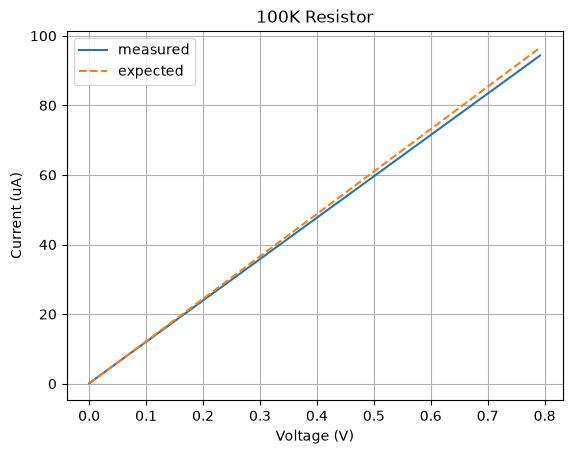

In [ ]:
v_vals = np.linspace(0, .8, 100, endpoint=False)
i_vals = []
for v in v_vals:
    qdac.ch01.v(v)
    i_vals.append(abs(qdac.ch02.i()))
    # time.sleep(.1)

plt.plot(v_vals, np.array(i_vals)*(1e6), label="measured")
plt.plot(v_vals, v_vals * ((1e6) / (8.2e3)), label="expected", linestyle="--")
plt.grid()
plt.xlabel("Voltage (V)")
plt.ylabel("Current (uA)")
plt.legend()
plt.title("8.2K Resistor")
# 0 - 10uA
# 0 - 100Ua

In [4]:
R = 8.2*1e3 # 8.2kOhm
CHANNEL = "ch01"

def set_flux_current(value): #  in uA
    voltage = value * 1e-6 * R
    if (voltage >= 10):
        raise ValueError("ERROR: Too high a voltage")
    getattr(qdac, CHANNEL).v(voltage)
    print("Set flux current to {} uA ({} V)".format(value, voltage))

def get_flux_current():
    voltage = getattr(qdac, CHANNEL).v()
    current = voltage / R * 1e6
    print("Current flux current is {} uA ({} V)".format(current, voltage))
    return current


In [ ]:


set_flux_current(163.55494302370272)
dtspec = PulseProbeSpectroscopy()
loc = run_and_save_sweep(sweep=dtspec, name=f"Saturation spectroscopy at {get_flux_current()} uA", data_dir="data")

Set flux current to 163.55494302370272 uA (1.3411505327943622 V)
Current flux current is 163.5541463414634 uA (1.341144 V)
[2026-10-06 15:29:47.908] [labcore.data.datadict_storage: INFO] Data location: data\2026-10-06\2026-10-06T152947_ac9cc2d1-Saturation spectroscopy at 163.5541463414634 uA\data.ddh5
[2026-10-06 15:29:58.315] [labcore.measurement.storage: INFO] The measurement has finished successfully and all of the data has been saved.


In [73]:
set_flux_current(395)

Set flux current to 395 uA (3.239 V)


In [6]:
@pointer(indep('current', unit='uA'))
def sweepcurrentinuA(start=1, stop=2, step = 0.5):
    current_list =np.arange(start, stop, step)
    for i in current_list:
        print("ENTER LOOP")
        set_flux_current(i)
        yield {"current": float(i)}

In [86]:
dtspec = PulseProbeSpectroscopy()

current_start = 380 # 850 # 
current_end = 410 # 865
# current_start = 155 # 4600-5000MHz
# current_end = 175
current_step=2

current_sweep = Sweep(sweepcurrentinuA.using(start=current_start, stop=current_end, step=current_step))
measurement = current_sweep @ dtspec


data_loc, _ = run_and_save_sweep(sweep=measurement, name=f'qubit_saturation_spec_vs_flux_{current_start}_{current_end}', data_dir="data")

[2026-10-10 17:59:35.172] [labcore.data.datadict_storage: INFO] Data location: data\2026-10-10\2026-10-10T175935_4319b74e-qubit_saturation_spec_vs_flux_380_410\data.ddh5
ENTER LOOP
Set flux current to 380 uA (3.1159999999999997 V)
ENTER LOOP
Set flux current to 382 uA (3.1323999999999996 V)
ENTER LOOP
Set flux current to 384 uA (3.1488 V)
ENTER LOOP
Set flux current to 386 uA (3.1652 V)
ENTER LOOP
Set flux current to 388 uA (3.1816 V)
ENTER LOOP
Set flux current to 390 uA (3.198 V)
ENTER LOOP
Set flux current to 392 uA (3.2144 V)
ENTER LOOP
Set flux current to 394 uA (3.2308 V)
ENTER LOOP
Set flux current to 396 uA (3.2472 V)
ENTER LOOP
Set flux current to 398 uA (3.2636 V)
ENTER LOOP
Set flux current to 400 uA (3.28 V)
ENTER LOOP
Set flux current to 402 uA (3.2963999999999998 V)
ENTER LOOP
Set flux current to 404 uA (3.3128 V)
ENTER LOOP
Set flux current to 406 uA (3.3292 V)
ENTER LOOP
Set flux current to 408 uA (3.3456 V)
[2026-10-10 18:03:43.612] [labcore.measurement.storage: INFO] 

In [74]:
rspec = FreqSweepProgram()
loc, _ = run_and_save_sweep(rspec,name=f"Resonator spectroscopy_at_{round(get_flux_current(), 2)}_uA", data_dir="data")

Current flux current is 394.9998780487805 uA (3.238999 V)
[2026-10-09 17:16:41.145] [labcore.data.datadict_storage: INFO] Data location: data\2026-10-09\2026-10-09T171641_1a72a87e-Resonator spectroscopy_at_395.0_uA\data.ddh5
[2026-10-09 17:16:47.721] [labcore.measurement.storage: INFO] The measurement has finished successfully and all of the data has been saved.
